[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ScriptsRemote/Transcend_SummerSchool/blob/main/Day4_LULC_and_Climate_with_RS/03_training_mapping_and_accuracy_es.ipynb)

# Día 4 - Uso y Cobertura del Suelo y Clima con Teledetección
## Sesión 3: Entrenamiento, mapeo y exactitud

| | |
|---|---|
| **Fecha** | 2026-10-15 (jueves) |
| **Horario** | 14:00 - 15:30 |
| **Entidad** | UoM |
| **Instructores** | Christhian, Gustavo |

### Contenido

> Del modelo al producto: **validación K-fold** (aleatoria y espacial), modelo final, mapa
> temático, área por clase y **exportación**; agricultura **bajo riego frente a secano** con firmas de época seca/húmeda
> y álgebra de mapas; **detección de cambios** con MapBiomas.

### Objetivos de aprendizaje

- [ ] Usar la validación cruzada K-fold para elegir la entrada del clasificador, y explicar por qué un
      K-fold **espacial** da una exactitud más honesta que uno aleatorio
- [ ] Entrenar el modelo final con todas las muestras, producir el mapa temático, calcular el área por
      clase y exportar el resultado (GeoTIFF, asset, CSV)
- [ ] Separar la agricultura bajo riego de la de secano a partir de su firma de NDVI en la época seca y en la
      húmeda
- [ ] Construir una matriz de cambio "de - a" con álgebra de mapas

### Datos necesarios

- Landsat 8/9 C2 L2, Sentinel-2 SR, NASADEM y **MapBiomas Bolivia Colección 3** (Earth Engine)
- `Assets/Day4/copacabana_samples.geojson` (las mismas muestras de las sesiones 1 y 2)

### Lo que ya vimos

Sesión 1: clasificadores y matriz de confusión. Sesión 2: mosaicos de época seca y húmeda, y la
lección de que **una sola división aleatoria 70/30 no es suficiente** para comparar entradas. Esta sesión parte
de ahí.

### Dos áreas de estudio

| Área | Uso |
|---|---|
| **Copacabana** (la misma de las sesiones 1 y 2) | K-fold, modelo final, mapa, área, exportación |
| **Área de riego** (orilla este del lago) | riego vs secano, detección de cambios |

---

## 3.1 - Configuración

In [5]:
# Librerías (descomente la línea de pip en un entorno nuevo, p. ej. Google Colab)
#%pip install -q earthengine-api geemap scikit-learn

import os
import ee                          # API de Google Earth Engine
import geemap                      # mapas interactivos para Earth Engine
import pandas as pd                # tablas (DataFrames)
import matplotlib.pyplot as plt    # gráficos

# scikit-learn: Random Forest y validación cruzada K-fold
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, cross_val_score

In [6]:
# Autenticar e inicializar Earth Engine
# >>> REEMPLAZAR por el id de su propio proyecto de Cloud <<<
EE_PROJECT = "ee-edwinyucra"

ee.Authenticate()
ee.Initialize(project=EE_PROJECT)

In [7]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [8]:
# Copacabana (sesiones 1 y 2): clasificación, validación y exportación
REGION = ee.Geometry.Polygon(
    [[[-69.1010932684908, -16.14842858486395],
      [-69.1010932684908, -16.17175891406604],
      [-69.06075284490682, -16.17175891406604],
      [-69.06075284490682, -16.14842858486395]]], None, False)

# Área de riego (orilla este del lago): riego vs secano y detección de cambios
IRR_REGION = ee.Geometry.Polygon(
    [[[-68.70649599980511, -16.007559642081016],
      [-68.70649599980511, -16.06431337741235],
      [-68.62581515263714, -16.06431337741235],
      [-68.62581515263714, -16.007559642081016]]], None, False)

Map = geemap.Map()
Map.centerObject(REGION.union(IRR_REGION, maxError=1), 10)
Map.add_basemap("SATELLITE")
Map.addLayer(REGION, {"color": "red"}, "Copacabana")
Map.addLayer(IRR_REGION, {"color": "yellow"}, "Irrigation area")
Map

Map(center=[-16.05715238619831, -68.73679819491656], controls=(WidgetControl(options=['position', 'transparent…

### Funciones del cubo de datos (del Día 3 y de la sesión 2)

Las mismas funciones de antes. `seasonal_mosaic` ahora recibe la **región** como argumento,
porque la usamos en las dos áreas.

In [9]:
def mask_clouds(image):
    # Bits de QA_PIXEL 1 (nube dilatada), 2 (cirros), 3 (nube) y 4 (sombra de nube)
    cloud_bits = (1 << 1) | (1 << 2) | (1 << 3) | (1 << 4)
    clear = image.select("QA_PIXEL").bitwiseAnd(cloud_bits).eq(0)
    return image.updateMask(clear)


def scale_and_rename(image):
    # Factor de escala de la Colección 2 -> reflectancia de superficie, y nombres de bandas legibles
    optical = image.select(["SR_B2", "SR_B3", "SR_B4", "SR_B5", "SR_B6", "SR_B7"])
    optical = optical.multiply(0.0000275).add(-0.2)
    return optical.rename(["Blue", "Green", "Red", "NIR", "SWIR1", "SWIR2"])


def add_indices(image):
    ndvi = image.normalizedDifference(["NIR", "Red"]).rename("NDVI")
    ndwi = image.normalizedDifference(["Green", "NIR"]).rename("NDWI")
    ndmi = image.normalizedDifference(["NIR", "SWIR1"]).rename("NDMI")
    evi = image.expression(
        "2.5 * (NIR - RED) / (NIR + 6 * RED - 7.5 * BLUE + 1)",
        {"NIR": image.select("NIR"), "RED": image.select("Red"), "BLUE": image.select("Blue")},
    ).rename("EVI")
    msavi = image.expression(
        "(2 * NIR + 1 - sqrt((2 * NIR + 1) ** 2 - 8 * (NIR - RED))) / 2",
        {"NIR": image.select("NIR"), "RED": image.select("Red")},
    ).rename("MSAVI")
    return image.addBands([ndvi, msavi, evi, ndwi, ndmi])


def seasonal_mosaic(region, start, end, max_cloud):
    # Landsat 8 + 9 de un período y una región: filtrar, limpiar, escalar, agregar índices, mediana
    collection = (ee.ImageCollection("LANDSAT/LC08/C02/T1_L2")
                    .merge(ee.ImageCollection("LANDSAT/LC09/C02/T1_L2"))
                    .filterBounds(region)
                    .filterDate(start, end)
                    .filter(ee.Filter.lt("CLOUD_COVER", max_cloud))
                    .map(mask_clouds)
                    .map(scale_and_rename)
                    .map(add_indices))
    return collection.median().clip(region)

In [10]:
# Época seca y húmeda del año agrícola 2023/24 (Copacabana)
dry = seasonal_mosaic(REGION, "2024-05-01", "2024-10-01", max_cloud=30)
wet = seasonal_mosaic(REGION, "2023-11-01", "2024-05-01", max_cloud=60)

# Pila con ambas estaciones, ΔNDVI y terreno (como en la sesión 2)
dry_s = dry.rename(dry.bandNames().map(lambda b: ee.String(b).cat("_dry")))
wet_s = wet.rename(wet.bandNames().map(lambda b: ee.String(b).cat("_wet")))
delta_ndvi = wet.select("NDVI").subtract(dry.select("NDVI")).rename("dNDVI")
elevation = ee.Image("NASA/NASADEM_HGT/001").select("elevation")
slope = ee.Terrain.slope(elevation).rename("slope")

stack = dry_s.addBands([wet_s, delta_ndvi, elevation, slope]).toFloat()

# Las tres entradas candidatas
DRY_BANDS = dry_s.bandNames().getInfo()
WET_BANDS = wet_s.bandNames().getInfo()
INPUTS = {
    "Dry": DRY_BANDS + ["elevation", "slope"],
    "Wet": WET_BANDS + ["elevation", "slope"],
    "Dry + wet": DRY_BANDS + WET_BANDS + ["dNDVI", "elevation", "slope"],
}

In [11]:
# Muestras (el mismo archivo de las sesiones 1 y 2)
SAMPLES_FILE = "/content/copacabana_samples.geojson"
SAMPLES_URL = ("https://raw.githubusercontent.com/ScriptsRemote/Transcend_SummerSchool/"
               "main/Assets/Day4/copacabana_samples.geojson")   # usado en Colab
CLASS_PROPERTY = "class"
NAME_PROPERTY = "class_name"

samples = geemap.coreutils.geojson_to_ee(SAMPLES_FILE if os.path.exists(SAMPLES_FILE) else SAMPLES_URL)

classes = (geemap.ee_to_df(samples)[[CLASS_PROPERTY, NAME_PROPERTY]]
           .drop_duplicates().sort_values(CLASS_PROPERTY).reset_index(drop=True))
CLASS_CODES = classes[CLASS_PROPERTY].astype(int).tolist()
CLASS_NAMES = classes[NAME_PROPERTY].tolist()
PALETTE = ["#2c7bb6", "#a21616", "#d8b365", "#2ae01a", "#cc7218"]
vis_classes = {"min": min(CLASS_CODES), "max": max(CLASS_CODES), "palette": PALETTE}

classes

,class,class_name
0,1,water
1,2,urban
2,3,agriculture
3,4,vegetation
4,5,soil


---

## 3.2 - Validación cruzada K-fold: dejar que los datos elijan la entrada

En la sesión 2 una sola división aleatoria 70/30 no pudo decir qué entrada era la mejor - el conjunto de prueba
era demasiado pequeño. La **validación cruzada K-fold** usa todas las muestras para la prueba:

1. dividir las muestras en **k pliegues (folds)** (aquí k = 5);
2. entrenar con 4 pliegues y probar con el 5.º;
3. repetir 5 veces, de modo que cada muestra se pruebe una vez;
4. informar la **media ± desviación estándar** de la exactitud.

### Pliegues aleatorios frente a pliegues espaciales

Nuestras muestras vienen de una **grilla de 100 m dentro de unos pocos polígonos**. Con pliegues **aleatorios**, un punto de prueba
casi siempre tiene un vecino de entrenamiento a 100 m - casi el mismo píxel - y la exactitud es
**demasiado optimista**. Con **pliegues espaciales**, el área se corta en bloques y todos los puntos de un
bloque van al mismo pliegue: el modelo se prueba en lugares que no ha visto (Roberts et al.,
2017).

> ¿Por qué bloques y no polígonos? Agrupar por `polygon_id` sería lo ideal, pero nuestro archivo tiene solo
> **un polígono de urbano** y dos de agricultura y suelo - con 5 pliegues, algunos pliegues no tendrían
> nada de urbano. Los bloques de 300 m (tres veces el espaciamiento de las muestras) mantienen cada clase en varios
> pliegues.

### Qué se ejecuta dónde

Hasta aquí **no se clasificó nada** - solo construimos la pila (seca, húmeda, ΔNDVI, terreno) y
cargamos las muestras. El K-fold no produce mapas: solo **prueba modelos sobre las muestras**.

| Paso | Dónde | Qué ocurre | Resultado |
|---|---|---|---|
| 1 | Earth Engine | `sampleRegions` lee las 25 bandas de la pila bajo cada una de las 488 muestras | **una tabla** (filas = píxeles, columnas = bandas + clase) |
| 2 | scikit-learn | 3 entradas × 5 pliegues = **15 Random Forests** entrenados y probados con esa tabla | exactitud media ± desviación estándar de cada entrada |
| 3 | Earth Engine (sección 3.3) | **un** Random Forest con la entrada ganadora y todas las muestras clasifica la imagen | el mapa final |

La tabla es pequeña (unos cientos de filas), así que los 15 modelos se ejecutan en segundos en su computadora.
La clasificación de la imagen - millones de píxeles - se queda en Earth Engine.

In [12]:
# 1. Earth Engine: valores de los píxeles de TODAS las bandas bajo cada muestra, con las coordenadas
pixels = stack.sampleRegions(collection=samples,
                             properties=[CLASS_PROPERTY, "longitude", "latitude"],
                             scale=30, tileScale=4)

# 2. A pandas; eliminar las filas con valores faltantes (p. ej. nubes en el mosaico de época húmeda)
df = geemap.ee_to_df(pixels).dropna()

# 3. Bloques espaciales de ~300 m (0.003 grados): cada punto recibe el id de su bloque
df["block"] = ((df["longitude"] // 0.003).astype(int).astype(str) + "_" +
               (df["latitude"] // 0.003).astype(int).astype(str))

print("Pixels:", len(df), "| spatial blocks:", df["block"].nunique())
df.groupby(CLASS_PROPERTY)["block"].nunique().rename("blocks per class")

Pixels: 269 | spatial blocks: 52


,blocks per class
class,
1,19
2,11
3,15
4,7


In [13]:
# El mismo Random Forest para cada prueba (100 árboles, como en Earth Engine)
rf_sk = RandomForestClassifier(n_estimators=100, random_state=42)

# Dos formas de construir los 5 pliegues
random_folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
spatial_folds = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

y = df[CLASS_PROPERTY]


def kfold(bands, folds, groups=None):
    # Exactitud global de los 5 pliegues
    return cross_val_score(rf_sk, df[bands], y, cv=folds, groups=groups, scoring="accuracy")


# Ejecutar ambos K-fold para cada una de las tres entradas
cv = {}
for name, bands in INPUTS.items():
    spatial = kfold(bands, spatial_folds, groups=df["block"])
    cv[name] = {"Random K-fold (mean)": kfold(bands, random_folds).mean(),
                "Spatial K-fold (mean)": spatial.mean(),
                "Spatial K-fold (std)": spatial.std()}
cv = pd.DataFrame(cv).T

cv.round(3)

,Random K-fold (mean),Spatial K-fold (mean),Spatial K-fold (std)
Dry,0.981,0.977,0.022
Wet,0.974,0.971,0.031
Dry + wet,0.974,0.970,0.037


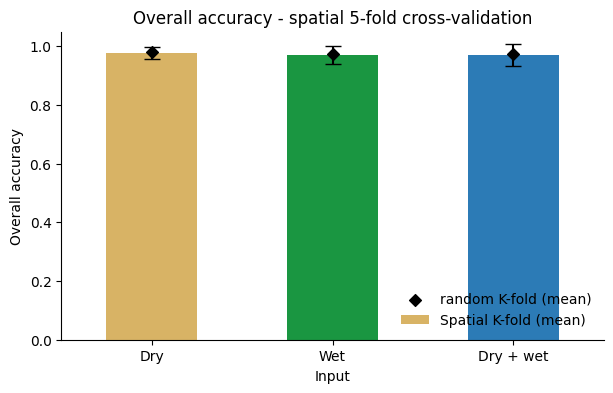

Input chosen by the spatial K-fold: Dry


In [14]:
# Media ± desviación estándar del K-fold espacial para cada entrada
ax = cv["Spatial K-fold (mean)"].plot.bar(yerr=cv["Spatial K-fold (std)"], capsize=6, rot=0,
                                          figsize=(7, 4), color=["#d8b365", "#1a9641", "#2c7bb6"])
ax.scatter(range(len(cv)), cv["Random K-fold (mean)"], color="black", marker="D", zorder=3,
           label="random K-fold (mean)")
ax.set_title("Overall accuracy - spatial 5-fold cross-validation")
ax.set_xlabel("Input")
ax.set_ylabel("Overall accuracy")
ax.set_ylim(0, 1.05)
ax.legend(frameon=False, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

# La entrada con la mayor exactitud en el K-fold espacial se usa para el mapa final
BEST = cv["Spatial K-fold (mean)"].idxmax()
print("Input chosen by the spatial K-fold:", BEST)

**Cómo leerlo.**

- Los **rombos negros** (pliegues aleatorios) casi siempre están **más arriba** que las barras (pliegues
  espaciales). Esa diferencia es el optimismo causado por la autocorrelación espacial.
- Las **barras de error** muestran cuánto cambia la exactitud de un pliegue a otro. Si las barras de dos
  entradas se superponen, son prácticamente equivalentes - elija la más simple si lo prefiere.
- La entrada con la mejor exactitud espacial (`BEST`) pasa al modelo final.

---

## 3.3 - Modelo final, mapa temático y área por clase

Después de la validación, el **modelo final se entrena con todas las muestras** - ya no hay razón para dejar
datos fuera. Su exactitud esperada es la estimada por el K-fold de arriba; no se puede
medir de nuevo con las mismas muestras.

In [15]:
# Random Forest final en Earth Engine: todas las muestras, entrada elegida por el K-fold
bands = INPUTS[BEST]
rf_final = ee.Classifier.smileRandomForest(numberOfTrees=100, seed=42).train(
    features=pixels, classProperty=CLASS_PROPERTY, inputProperties=bands)

classified = stack.select(bands).classify(rf_final).rename("class")

# Posprocesamiento: el filtro de mayoría (3 x 3 píxeles) elimina los píxeles aislados ("sal y pimienta")
classified_clean = classified.focalMode(radius=1, kernelType="square").rename("class").clip(REGION)

Map = geemap.Map()
Map.centerObject(REGION, 14)
Map.addLayer(dry, {"bands": ["Red", "Green", "Blue"], "min": 0, "max": 0.3}, "RGB dry season", False)
Map.addLayer(classified, vis_classes, f"RF {BEST} - raw", False)
Map.addLayer(classified_clean, vis_classes, f"RF {BEST} - majority filter")
Map.add_legend(title=f"Final map ({BEST})", legend_dict=dict(zip(CLASS_NAMES, PALETTE)))
Map

Map(center=[-16.16009383889344, -69.08092305669851], controls=(WidgetControl(options=['position', 'transparent…

Cambie entre las capas *raw* (sin filtrar) y *majority filter* (filtro de mayoría): el filtro elimina los píxeles aislados y
hace que el mapa sea más fácil de leer, a costa de borrar objetos muy pequeños.

### Área por clase

`ee.Image.pixelArea()` da el área de cada píxel (m²). Un reductor **agrupado** suma el área de
los píxeles de cada clase.

In [16]:
# Suma del área de los píxeles, agrupada por clase
area = (ee.Image.pixelArea().divide(1e6)                     # m2 -> km2
          .addBands(classified_clean)
          .reduceRegion(reducer=ee.Reducer.sum().group(groupField=1, groupName="class"),
                        geometry=REGION, scale=30, maxPixels=1e10))

df_area = pd.DataFrame(area.getInfo()["groups"]).rename(columns={"sum": "area_km2"})
df_area["class_name"] = df_area["class"].map(dict(zip(CLASS_CODES, CLASS_NAMES)))
df_area["percent"] = 100 * df_area["area_km2"] / df_area["area_km2"].sum()
df_area.round(2)

,class,area_km2,class_name,percent
0,1,3.99,water,35.80
1,2,1.78,urban,15.98
2,3,3.17,agriculture,28.42
3,4,2.21,vegetation,19.80


> **Contar píxeles no es lo mismo que estimar el área.** Cada clase tiene errores de omisión y de comisión,
> así que el área mapeada está sesgada. La buena práctica es corregirla con la matriz de confusión
> e informar un intervalo de confianza (Olofsson et al., 2014). Aquí informamos el **área mapeada**.

---

## 3.4 - Exportar el mapa temático

Tres formas, según lo que necesite:

| Salida | Herramienta | Cuándo |
|---|---|---|
| GeoTIFF en su computadora | `geemap.ee_export_image` | áreas pequeñas, para abrir en QGIS ahora |
| GeoTIFF en Google Drive | `ee.batch.Export.image.toDrive` | áreas grandes (se ejecuta en segundo plano) |
| **Asset** de Earth Engine | `ee.batch.Export.image.toAsset` | para reutilizar el mapa en otros scripts (p. ej. como máscara de uso del suelo en la sesión 4) |

El mapa se exporta como **enteros** (`toByte`) en **UTM zona 19 Sur** (EPSG:32719), la
proyección de la región, a 30 m.

In [17]:
final_map = classified_clean.toByte()

# 1. Descarga directa a la carpeta de trabajo (áreas pequeñas)
geemap.ee_export_image(final_map, filename="copacabana_lulc_rf.tif",
                       scale=30, region=REGION, crs="EPSG:32719")

# 2. Tabla de áreas como CSV
df_area.to_csv("copacabana_lulc_rf_area.csv", index=False)
print("Saved: copacabana_lulc_rf.tif and copacabana_lulc_rf_area.csv")

Generating URL ...
Please wait ...
Data downloaded to /content/copacabana_lulc_rf.tif
Saved: copacabana_lulc_rf.tif and copacabana_lulc_rf_area.csv


In [18]:
# 3. Exportaciones en segundo plano: Google Drive y asset de Earth Engine (sígalas en el panel Tasks)
task_drive = ee.batch.Export.image.toDrive(
    image=final_map, description="copacabana_lulc_rf", folder="TRANSCEND",
    region=REGION, scale=30, crs="EPSG:32719", maxPixels=1e10)

task_asset = ee.batch.Export.image.toAsset(
    image=final_map, description="copacabana_lulc_rf_asset",
    assetId=f"projects/{EE_PROJECT}/assets/copacabana_lulc_rf",
    region=REGION, scale=30, crs="EPSG:32719", maxPixels=1e10)

task_drive.start()
task_asset.start()
print("Drive:", task_drive.status()["state"], "| Asset:", task_asset.status()["state"])

Drive: READY | Asset: READY


---

## 3.5 - Agricultura bajo riego frente a secano

Ahora pasamos al **área de riego** en la orilla este del lago. La pregunta no es "¿qué
clase es este píxel?" sino **"¿esta agricultura es bajo riego o de secano?"** - y se puede responder
con la firma estacional y el **álgebra de mapas**, sin entrenar un nuevo clasificador.

| | Época seca (may - sep) | Época húmeda (dic - mar) |
|---|---|---|
| Parcela de **secano** | sin agua -> en descanso, suelo desnudo, **NDVI bajo** | el cultivo crece con la lluvia -> **NDVI alto** |
| Parcela **bajo riego** | agua de canales / pozos -> el cultivo (a menudo alfalfa, forraje) se mantiene verde, **NDVI alto** | NDVI alto |

La teledetección del riego se basa justamente en este contraste: las parcelas bajo riego se mantienen verdes
cuando la lluvia no lo explica (Ozdogan et al., 2010).

### Paso 1 - ¿Dónde está la agricultura? (MapBiomas)

Aquí **no** reutilizamos el modelo de Copacabana - sus muestras no representan esta área. La
máscara de agricultura viene de **MapBiomas Bolivia Colección 3** (2024), con las mismas clases usadas
en la sesión 4: 18 Agricultura, 39 Soya, 40 Arroz, 72 Otros cultivos y 21 Mosaico de usos.

In [19]:
# MapBiomas Bolivia Colección 3 (una banda por año: classification_1985 ... classification_2024)
mapbiomas = ee.Image("projects/mapbiomas-public/assets/bolivia/lulc/collection3/mapbiomas_bolivia_collection3_integration_v1")

AGRI_CLASSES = [18, 39, 40, 72, 21]
agri = (mapbiomas.select("classification_2024").clip(IRR_REGION)
          .remap(AGRI_CLASSES, [1] * len(AGRI_CLASSES)).rename("agriculture"))

# Dos parcelas de referencia dibujadas sobre la imagen de alta resolución
parcel_a = ee.Geometry.Polygon(
    [[[-68.69527702768536, -16.048514897003855], [-68.69601731737347, -16.048576761262648],
      [-68.69600658853741, -16.04888608226832], [-68.69551306207867, -16.049896527539104],
      [-68.69510536630841, -16.04985528497534], [-68.69471912821027, -16.0496078294134],
      [-68.6939144655058, -16.048824218105608], [-68.6944723649809, -16.046772379155605],
      [-68.69580274065228, -16.047339472436242]]])
parcel_b = ee.Geometry.Polygon([[[-68.69848347808438, -16.015016672332564],
          [-68.69852639342862, -16.01905910933535],
          [-68.69623042251187, -16.019327227261527],
          [-68.69588709975797, -16.015181671363898],
          [-68.69601584579068, -16.014366987635658],
          [-68.69863368178922, -16.01420198793092],
          [-68.69859076644498, -16.014408237540525]]])

Map = geemap.Map()
Map.centerObject(IRR_REGION, 13)
Map.add_basemap("SATELLITE")
Map.addLayer(agri, {"palette": ["#e6b800"]}, "Agriculture 2024 (MapBiomas)", True, 0.6)
Map.addLayer(parcel_a, {"color": "cyan"}, "Parcel A")
Map.addLayer(parcel_b, {"color": "magenta"}, "Parcel B")
Map

Map(center=[-16.035936422472712, -68.66615557621901], controls=(WidgetControl(options=['position', 'transparen…

### Paso 2 - Observar el área en las dos estaciones

Antes de cualquier número, **observe**. Construimos los mosaicos de época seca y húmeda del área de riego
(Landsat, los mismos períodos que en Copacabana) y comparamos tres cosas:

- **RGB** - lo que ve el ojo: parcelas marrones en la época seca, verdes en la época húmeda;
- **NDVI** - vegetación verde;
- **NDMI** - **agua** en las hojas y el suelo, $(NIR - SWIR1)/(NIR + SWIR1)$. Una parcela bajo riego
  no solo está verde: está **húmeda** cuando todo a su alrededor está seco. El NDMI reacciona a esa agua incluso
  antes de que la planta se ponga más verde, así que es un buen segundo testigo del riego.

In [20]:
# Mosaicos estacionales del área de riego (Landsat 8 + 9, año agrícola 2023/24)
dry_irr = seasonal_mosaic(IRR_REGION, "2024-05-01", "2024-10-01", max_cloud=30)
wet_irr = seasonal_mosaic(IRR_REGION, "2023-11-01", "2024-05-01", max_cloud=60)

ndvi_dry, ndvi_wet = dry_irr.select("NDVI"), wet_irr.select("NDVI")
ndmi_dry, ndmi_wet = dry_irr.select("NDMI"), wet_irr.select("NDMI")

# Parámetros de visualización
vis_rgb = {"bands": ["Red", "Green", "Blue"], "min": 0.0, "max": 0.3}
vis_ndvi = {"min": 0.0, "max": 0.7, "palette": ["#a6611a", "#f5f5dc", "#a6d96a", "#1a9641", "#00441b"]}
vis_ndmi = {"min": -0.3, "max": 0.4, "palette": ["#8c510a", "#f6e8c3", "#80cdc1", "#01665e"]}

# RGB: época seca a la izquierda, época húmeda a la derecha
Map = geemap.Map()
Map.centerObject(IRR_REGION, 13)
Map.split_map(left_layer=geemap.ee_tile_layer(dry_irr, vis_rgb, "RGB dry"),
              right_layer=geemap.ee_tile_layer(wet_irr, vis_rgb, "RGB wet"),
              left_label="RGB - dry season", right_label="RGB - wet season")
Map

Map(center=[-16.035936422472712, -68.66615557621901], controls=(ZoomControl(options=['position', 'zoom_in_text…

In [21]:
# NDVI: época seca a la izquierda, época húmeda a la derecha
Map = geemap.Map()
Map.centerObject(IRR_REGION, 13)
Map.split_map(left_layer=geemap.ee_tile_layer(ndvi_dry, vis_ndvi, "NDVI dry"),
              right_layer=geemap.ee_tile_layer(ndvi_wet, vis_ndvi, "NDVI wet"),
              left_label="NDVI - dry season", right_label="NDVI - wet season")
Map.add_colorbar(vis_ndvi, label="NDVI")
Map

Map(center=[-16.035936422472712, -68.66615557621901], controls=(ZoomControl(options=['position', 'zoom_in_text…

In [22]:
# NDMI: época seca a la izquierda, época húmeda a la derecha
Map = geemap.Map()
Map.centerObject(IRR_REGION, 13)
Map.split_map(left_layer=geemap.ee_tile_layer(ndmi_dry, vis_ndmi, "NDMI dry"),
              right_layer=geemap.ee_tile_layer(ndmi_wet, vis_ndmi, "NDMI wet"),
              left_label="NDMI - dry season", right_label="NDMI - wet season")
Map.add_colorbar(vis_ndmi, label="NDMI")
Map

Map(center=[-16.035936422472712, -68.66615557621901], controls=(ZoomControl(options=['position', 'zoom_in_text…

### Las diferencias entre las estaciones

Tres capas resumen el cambio (use el control de capas para cambiar):

- **ΔNDVI** y **ΔNDMI** = húmeda menos seca. Valores **altos**: la parcela reverdece / se humedece solo con
  la lluvia (secano). Valores **cercanos a cero** con NDVI alto en ambas estaciones: verde todo el año (bajo riego,
  o humedal permanente).
- **Composición multitemporal** - una imagen en color hecha de índices en lugar de bandas:
  **R = NDVI húmeda, G = NDVI seca, B = NDMI seca**.

| Color | Significado |
|---|---|
| **rojo** | verde solo en la época húmeda -> **secano** |
| **blanco / cian claro** | verde y húmedo también en la época seca -> **bajo riego** (o humedal) |
| **oscuro** | NDVI bajo en ambas estaciones -> suelo desnudo, descanso, urbano |

In [23]:
# Diferencias entre las estaciones (húmeda - seca)
dndvi = ndvi_wet.subtract(ndvi_dry).rename("dNDVI")
dndmi = ndmi_wet.subtract(ndmi_dry).rename("dNDMI")
vis_diff = {"min": -0.2, "max": 0.4, "palette": ["#2166ac", "#f7f7f7", "#b2182b"]}

# Composición multitemporal: R = NDVI húmeda, G = NDVI seca, B = NDMI seca
multidate = ee.Image.cat([ndvi_wet, ndvi_dry, ndmi_dry]).rename(["R", "G", "B"])
vis_multi = {"bands": ["R", "G", "B"], "min": [0.0, 0.0, -0.3], "max": [0.6, 0.6, 0.3]}

Map = geemap.Map()
Map.centerObject(IRR_REGION, 13)
Map.addLayer(dndvi, vis_diff, "ΔNDVI (wet - dry)", False)
Map.addLayer(dndmi, vis_diff, "ΔNDMI (wet - dry)", False)
Map.addLayer(multidate, vis_multi, "Multi-date: R=NDVI wet, G=NDVI dry, B=NDMI dry")
Map.addLayer(parcel_a, {"color": "cyan"}, "Parcel A")
Map.addLayer(parcel_b, {"color": "magenta"}, "Parcel B")
Map.add_colorbar(vis_diff, label="Δ index (wet - dry): blue = greener/wetter in the dry season")
Map

Map(center=[-16.035936422472712, -68.66615557621901], controls=(WidgetControl(options=['position', 'transparen…

### Paso 3 - La firma de dos parcelas a lo largo de un año

Todavía no sabemos si las parcelas A y B son bajo riego - **las curvas de NDVI y NDMI nos lo
dirán**. Para las curvas usamos **Sentinel-2** (píxeles de 10 m, una nueva imagen cada ~5 días): más fechas
y más píxeles dentro de cada parcela que Landsat.

In [24]:
def mask_s2(image):
    # Conservar solo vegetación (4), suelo desnudo (5) y agua (6) de la Scene Classification Layer
    scl = image.select("SCL")
    return image.updateMask(scl.eq(4).Or(scl.eq(5)).Or(scl.eq(6)))


s2 = (ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
        .filterBounds(IRR_REGION)
        .filterDate("2023-07-01", "2024-10-01")          # un año agrícola completo
        .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 60))
        .map(mask_s2))


def index_series(parcel):
    # NDVI y NDMI medios de la parcela en cada imagen Sentinel-2 (las fechas con nubes se descartan)
    def parcel_indices(image):
        ndvi = image.normalizedDifference(["B8", "B4"]).rename("NDVI")     # B8 = NIR, B4 = rojo
        ndmi = image.normalizedDifference(["B8", "B11"]).rename("NDMI")    # B11 = SWIR1
        stats = ndvi.addBands(ndmi).reduceRegion(reducer=ee.Reducer.mean(), geometry=parcel, scale=10)
        return ee.Feature(None, stats).set("date", image.date().format("YYYY-MM-dd"))

    # ee.FeatureCollection(...) convierte el resultado de map() en una tabla que geemap puede leer
    fc = ee.FeatureCollection(s2.map(parcel_indices)).filter(ee.Filter.notNull(["NDVI", "NDMI"]))
    table = geemap.ee_to_df(fc)
    table["date"] = pd.to_datetime(table["date"])
    return table.sort_values("date").set_index("date")[["NDVI", "NDMI"]]


series_a = index_series(parcel_a)
series_b = index_series(parcel_b)

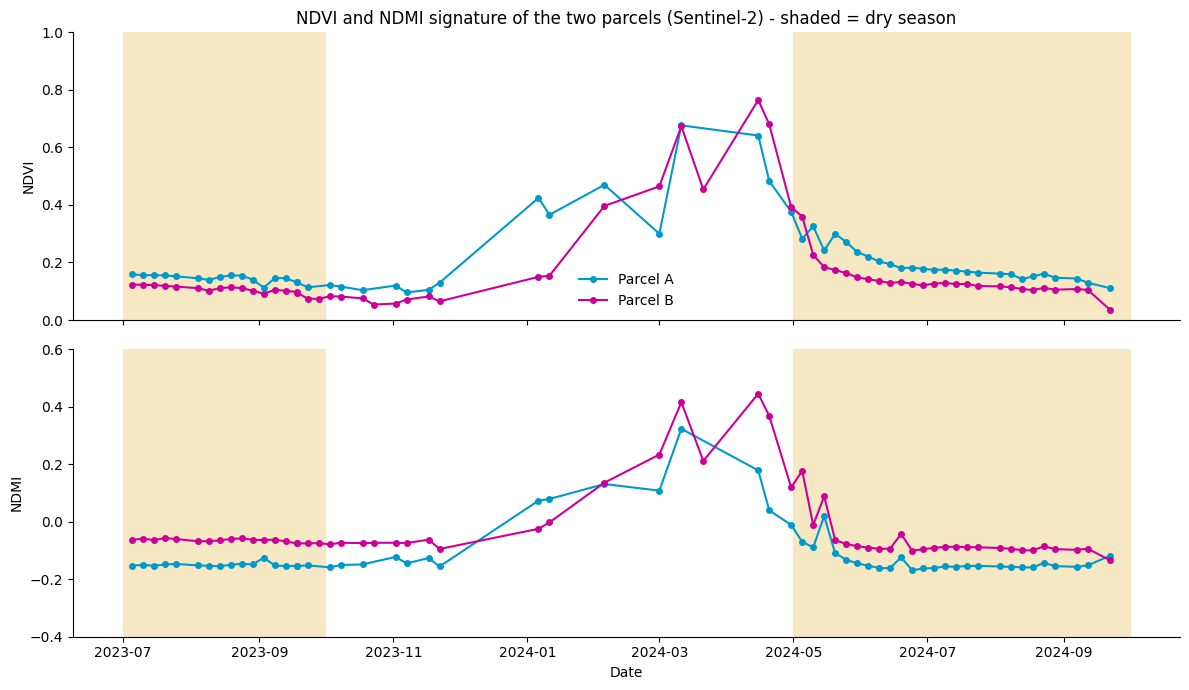

In [25]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

for ax, index, limits in [(axes[0], "NDVI", (0, 1)), (axes[1], "NDMI", (-0.4, 0.6))]:
    # Épocas secas sombreadas
    for start, end in [("2023-07-01", "2023-10-01"), ("2024-05-01", "2024-10-01")]:
        ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color="#f6e8c3", zorder=0)

    ax.plot(series_a.index, series_a[index], marker="o", markersize=4, color="#0099cc", label="Parcel A")
    ax.plot(series_b.index, series_b[index], marker="o", markersize=4, color="#cc0099", label="Parcel B")
    ax.set_ylabel(index)
    ax.set_ylim(*limits)
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_title("NDVI and NDMI signature of the two parcels (Sentinel-2) - shaded = dry season")
axes[0].legend(frameon=False)
axes[1].set_xlabel("Date")
plt.tight_layout()
plt.show()

**Cómo leerlo.**

- Una parcela de **secano** tiene **un solo pico** en la época húmeda (enero - marzo) y se mantiene baja en la
  época seca sombreada.
- Una parcela **bajo riego** se mantiene **verde dentro del área sombreada**, o muestra picos desfasados
  respecto a la lluvia (p. ej. un segundo corte de alfalfa en julio - agosto).
- Una curva que está baja todo el año es tierra en descanso, o una parcela que no se cultivó ese año.
- El **NDMI** confirma el agua: una parcela bajo riego mantiene el NDMI por encima de su entorno en la época
  seca; una de secano baja a valores negativos (suelo seco y rastrojo seco).

Decida para A y B antes de continuar. Los umbrales del siguiente paso deben coincidir con lo que ve
aquí.

### Paso 4 - Álgebra de mapas: bajo riego, secano o en descanso

Dentro de la máscara de agricultura, dos mosaicos estacionales de Landsat y dos umbrales:

| Regla | Clase |
|---|---|
| NDVI seca > `T_DRY` | **bajo riego** (verde sin lluvia) |
| NDVI seca ≤ `T_DRY` y NDVI húmeda > `T_WET` | **secano** (verde solo con lluvia) |
| en otro caso | **en descanso / no cultivado** |

In [26]:
# NDVI y NDMI estacionales de las dos parcelas (mosaicos Landsat del paso 2) - para verificar los umbrales
seasonal = ee.Image.cat([ndvi_dry.rename("NDVI_dry"), ndvi_wet.rename("NDVI_wet"),
                         ndmi_dry.rename("NDMI_dry"), ndmi_wet.rename("NDMI_wet")])

check = pd.DataFrame({
    name: seasonal.reduceRegion(ee.Reducer.mean(), geom, 10).getInfo()
    for name, geom in [("Parcel A", parcel_a), ("Parcel B", parcel_b)]
}).T
check.round(2)

,NDMI_dry,NDMI_wet,NDVI_dry,NDVI_wet
Parcel A,-0.12,0.14,0.19,0.47
Parcel B,-0.07,0.14,0.16,0.40


In [27]:
# >>> Umbrales: ajústelos con las firmas y la tabla de arriba <<<
T_DRY = 0.35     # NDVI en la época seca por encima de este valor = verde sin lluvia
T_WET = 0.30     # NDVI en la época húmeda por encima de este valor = cultivo que crece con la lluvia

# Álgebra de mapas: comenzar con 3 (descanso) y sobrescribir donde cada regla es verdadera
irrigation = (ee.Image(3)
                .where(ndvi_dry.lte(T_DRY).And(ndvi_wet.gt(T_WET)), 2)   # secano
                .where(ndvi_dry.gt(T_DRY), 1)                            # bajo riego
                .updateMask(agri)                                        # solo agricultura
                .rename("irrigation"))

IRR_NAMES = ["Irrigated", "Rainfed", "Fallow / not cultivated"]
IRR_PALETTE = ["#0571b0", "#e6b800", "#bababa"]
vis_irr = {"min": 1, "max": 3, "palette": IRR_PALETTE}

Map = geemap.Map()
Map.centerObject(IRR_REGION, 13)
Map.add_basemap("SATELLITE")
Map.addLayer(irrigation, vis_irr, "Irrigated / rainfed / fallow")
Map.addLayer(parcel_a, {"color": "cyan"}, "Parcel A")
Map.addLayer(parcel_b, {"color": "magenta"}, "Parcel B")
Map.add_legend(title="Agriculture 2023/24", legend_dict=dict(zip(IRR_NAMES, IRR_PALETTE)))
Map

Map(center=[-16.035936422472712, -68.66615557621901], controls=(WidgetControl(options=['position', 'transparen…

In [28]:
# Área de cada tipo de agricultura (km2)
irr_area = (ee.Image.pixelArea().divide(1e6).addBands(irrigation)
              .reduceRegion(reducer=ee.Reducer.sum().group(groupField=1, groupName="type"),
                            geometry=IRR_REGION, scale=30, maxPixels=1e10))

df_irr = pd.DataFrame(irr_area.getInfo()["groups"]).rename(columns={"sum": "area_km2"})
df_irr["type"] = df_irr["type"].map(dict(zip([1, 2, 3], IRR_NAMES)))
df_irr.round(2)

,area_km2,type
0,4.51,Irrigated
1,29.88,Rainfed
2,2.45,Fallow / not cultivated


> **Límites de la regla.** Los umbrales son una simplificación: los humedales cerca del lago, un cultivo
> de secano tardío o un forraje perenne también pueden estar verdes en la época seca. Por eso la regla
> debe verificarse con conocimiento de campo o puntos de referencia. Las áreas bajo riego son donde la ET
> supera la lluvia en la época seca - el balance hídrico de la sesión 4 muestra de dónde
> debe venir esa agua.

---

## 3.6 - Detección de cambios con álgebra de mapas (MapBiomas)

Para detectar cambios necesitamos **dos mapas clasificados de la misma área** en dos fechas. Aquí usamos los
mapas de MapBiomas de **2000** y **2024** para mantener el foco en el método. **La lógica es exactamente la
misma con sus propios mapas de clasificación** - clasifique dos (o más) años con el flujo de trabajo de las
sesiones 1-3 y aplique la misma álgebra.

### Paso 1 - La misma leyenda en ambos años

MapBiomas tiene muchas clases; las agrupamos en 5 grandes grupos para que la matriz de cambio siga siendo legible.

In [34]:
# Clases de MapBiomas -> 5 grupos (códigos de la leyenda de MapBiomas Bolivia)
GROUPS = {
    1: [3, 4, 6, 10, 11, 12, 13, 63, 66, 77, 81, 82],     # vegetación natural
    2: [14, 15, 18, 21, 39, 40, 72],                       # agropecuario (agricultura + pasto)
    3: [26, 31, 33, 34],                                   # agua
    4: [24],                                               # urbano
    5: [22, 23, 25, 29, 30, 61, 68, 92],                   # otras áreas sin vegetación
}
GROUP_NAMES = {1: "Natural vegetation", 2: "Farming", 3: "Water", 4: "Urban", 5: "Non-vegetated"}
GROUP_PALETTE = ["#1f8d49", "#ffefc3", "#2532e4", "#d4271e", "#db4d4f"]

# remap necesita dos listas planas: códigos antiguos y códigos nuevos
old_codes = [c for codes in GROUPS.values() for c in codes]
new_codes = [g for g, codes in GROUPS.items() for c in codes]


def lulc_groups(year):
    # Mapa de MapBiomas de un año, agrupado en las 5 clases
    return (mapbiomas.select(f"classification_{year}").clip(IRR_REGION)
              .remap(old_codes, new_codes).rename("group"))


YEAR_1, YEAR_2 = 1990, 2024
lulc_1 = lulc_groups(YEAR_1)
lulc_2 = lulc_groups(YEAR_2)

vis_groups = {"min": 1, "max": 5, "palette": GROUP_PALETTE}
Map = geemap.Map()
Map.centerObject(IRR_REGION, 13)
Map.split_map(left_layer=geemap.ee_tile_layer(lulc_1, vis_groups, str(YEAR_1)),
              right_layer=geemap.ee_tile_layer(lulc_2, vis_groups, str(YEAR_2)),
              left_label=str(YEAR_1), right_label=str(YEAR_2))
Map.add_legend(title="Land use groups", legend_dict=dict(zip(GROUP_NAMES.values(), GROUP_PALETTE)))
Map

Map(center=[-16.035936422472712, -68.66615557621901], controls=(ZoomControl(options=['position', 'zoom_in_text…

### Paso 2 - El código de transición

Una línea de álgebra de mapas combina los dos mapas:

$$\text{transición} = \text{clase}_{2000} \times 10 + \text{clase}_{2024}$$

Un píxel que era vegetación natural (1) y pasó a agropecuario (2) recibe **12**; un píxel que siguió
siendo agropecuario recibe **22**. Con los códigos originales de MapBiomas (hasta 92) el multiplicador sería **100**
en lugar de 10 - la idea es la misma.

In [30]:
# Código de transición: primer dígito = clase en YEAR_1, segundo dígito = clase en YEAR_2
transition = lulc_1.multiply(10).add(lulc_2).rename("transition")

# Área de cada transición (km2), como una matriz "de - a"
trans_area = (ee.Image.pixelArea().divide(1e6).addBands(transition)
                .reduceRegion(reducer=ee.Reducer.sum().group(groupField=1, groupName="code"),
                              geometry=IRR_REGION, scale=30, maxPixels=1e10))

df_trans = pd.DataFrame(trans_area.getInfo()["groups"]).rename(columns={"sum": "area_km2"})
df_trans["from"] = (df_trans["code"] // 10).map(GROUP_NAMES)
df_trans["to"] = (df_trans["code"] % 10).map(GROUP_NAMES)

matrix = df_trans.pivot_table(index="from", columns="to", values="area_km2", fill_value=0)
matrix.round(2)

to,Farming,Natural vegetation,Non-vegetated,Urban,Water
from,,,,,
Farming,15.95,0.84,0.01,0.07,0.03
Natural vegetation,20.79,12.92,0.02,0.15,0.16
Non-vegetated,0.07,0.13,0.06,0.00,0.24
Urban,0.01,0.00,0.00,2.22,0.04
Water,0.01,0.15,0.03,0.01,0.28


**Cómo leer la matriz.** Las filas son la clase en 2000, las columnas la clase en 2024. La
**diagonal** es lo que no cambió; todo lo que está fuera de la diagonal es cambio. Por ejemplo, la
celda *Vegetación natural -> Agropecuario* es el área convertida a agricultura o pasto.

### Paso 3 - ¿Dónde cambió?

In [31]:
# Ganancias de agropecuario y urbano entre los dos años (todo lo demás transparente)
farming_gain = lulc_1.neq(2).And(lulc_2.eq(2)).selfMask()
farming_loss = lulc_1.eq(2).And(lulc_2.neq(2)).selfMask()
urban_gain = lulc_1.neq(4).And(lulc_2.eq(4)).selfMask()

Map = geemap.Map()
Map.centerObject(IRR_REGION, 13)
Map.add_basemap("SATELLITE")
Map.addLayer(farming_gain, {"palette": ["#e6b800"]}, f"Farming gain {YEAR_1}-{YEAR_2}")
Map.addLayer(farming_loss, {"palette": ["#7b3294"]}, f"Farming loss {YEAR_1}-{YEAR_2}")
Map.addLayer(urban_gain, {"palette": ["#d4271e"]}, f"Urban gain {YEAR_1}-{YEAR_2}")
Map.add_legend(title=f"Change {YEAR_1}-{YEAR_2}",
               legend_dict={"Farming gain": "#e6b800", "Farming loss": "#7b3294", "Urban gain": "#d4271e"})
Map

Map(center=[-16.035936422472712, -68.66615557621901], controls=(WidgetControl(options=['position', 'transparen…

---

## 3.7 - Ejercicio

1. **K-fold.** Cambie el tamaño del bloque de 0.003° (~300 m) a 0.006° (~600 m). ¿Qué pasa con la
   diferencia entre el K-fold aleatorio y el espacial?
2. **Umbrales.** Dibuje dos parcelas más en el área de riego, grafique sus firmas y ajuste
   `T_DRY` y `T_WET`. ¿Cuánto cambia el área bajo riego?
   Luego agregue una segunda condición con el **NDMI seca** (p. ej. bajo riego = NDVI seca > `T_DRY` **y** NDMI
   seca > 0). ¿Elimina humedales o falsos positivos?
3. **Cambio.** Repita la sección 3.6 para 1990 - 2024 y 2010 - 2024. ¿Cuándo ocurrió la mayor parte de la
   ganancia de agropecuario?
4. **Sus propios mapas.** Clasifique Copacabana para dos años con el flujo de trabajo de este notebook y
   construya la matriz de transición con sus mapas en lugar de MapBiomas.

**Entregable**: la tabla del K-fold, el mapa exportado, el área bajo riego / de secano y
la matriz de cambio, con un párrafo corto sobre cada uno.

---

## Referencias

- Roberts, D. R. et al. (2017). Cross-validation strategies for data with temporal, spatial,
  hierarchical, or phylogenetic structure. *Ecography*, 40(8), 913-929.
  <https://doi.org/10.1111/ecog.02881>
- Olofsson, P. et al. (2014). Good practices for estimating area and assessing accuracy of land
  change. *Remote Sensing of Environment*, 148, 42-57.
  <https://ui.adsabs.harvard.edu/abs/2014RSEnv.148...42O/abstract>
- Ozdogan, M., Yang, Y., Allez, G., Cervantes, C. (2010). Remote sensing of irrigated
  agriculture: opportunities and challenges. *Remote Sensing*, 2(9), 2274-2304.
  <https://doi.org/10.3390/rs2092274>
- Souza, C. M. et al. (2020). Reconstructing three decades of land use and land cover changes in
  Brazilian biomes with Landsat archive and Earth Engine. *Remote Sensing*, 12(17), 2735.
  <https://doi.org/10.3390/rs12172735>
- MapBiomas Bolivia: <https://bolivia.mapbiomas.org>
- scikit-learn - validación cruzada: <https://scikit-learn.org/stable/modules/cross_validation.html>
- Earth Engine - exportación de imágenes: <https://developers.google.com/earth-engine/guides/exporting_images>